We build a two-layer neural network to classify make_moons.

input(2) -> hidden layer (H tanh units) -> output (1 sigmoid unit)

Shapes used:

X: (m, 2)  m examples, 2 features

y: (m, 1)  0-1 classifier

W1: (2, H)  b1: (1, H)  first layer

W2: (H, 1)  b2: (1, 1)  second layer

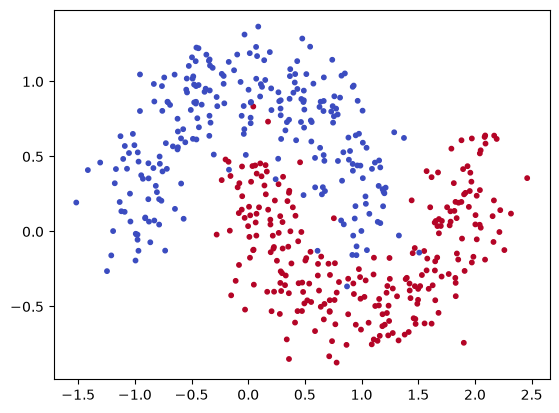

In [3]:
import numpy as np
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples = 500, noise = 0.2, random_state =40)
plt.scatter(X[:,0], X[:,1], c=y, cmap = "coolwarm", s=10)
plt.show()

In [4]:
y = y.reshape(-1,1)
from sklearn.model_selection import train_test_split
X, X_test, y, y_test = train_test_split(X, y, test_size = 0.2, random_state = 30)

In [5]:
# this will be denoted by p in the parameters later
def init_params(n_in, n_hidden, rng):
    return {
        "W1": rng.normal(0.0, 1.0/np.sqrt(n_in), size = (n_in, n_hidden)),
        "b1": np.zeros((1, n_hidden)),
        "W2": rng.normal(0.0, 1.0/np.sqrt(n_hidden), size = (n_hidden, 1)),
        "b2": np.zeros((1, 1)),
    }

In [6]:
def sigmoid(z):
    return 1.0/(1.0 + np.exp(-z))

In [7]:
def forward(X, p):
    Z1 = X @ p["W1"] + p["b1"]
    A1 = np.tanh(Z1)
    Z2 = A1 @ p["W2"] + p["b2"]
    A2 = sigmoid(Z2)
    cache = {"A1": A1, "A2": A2}
    return A2, cache

In [8]:
def bce_loss(a, y, eps = 1e-12):
    a = np.clip(a, eps, 1-eps)
    return -np.mean(y*np.log(a) + (1-y)*np.log(1-a))

$$Z_1 = X W_1 + b_1$$
$$A_1 = tanh(Z_1)$$
$$Z_2 = A_1 W_2 +b_2$$
$$A_2 = sigmoid(Z_2)$$
$$L = mean[-y\log(A_2)-(1-y)\log(1-A_2)]$$

In [9]:
def gradients(X, y, p, cache):
    m = X.shape[0]
    A1, A2 = cache["A1"], cache["A2"]

    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    dA1 = dZ2 @ p["W2"].T
    dZ1 = dA1 * (1 - A1**2)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2":dW2, "b2": db2}

#### Check if the gradient is correct

In [16]:
def grad_check(X, y, p, h=1e-5):
    a, cache = forward(X, p)
    grads = gradients(X, y, p, cache)

    for k in p:
        num = np.zeros_like(p[k])
        for idx in np.ndindex(p[k].shape):
            old = p[k][idx]
            p[k][idx] = old + h
            loss_plus = bce_loss(forward(X, p)[0], y)
            p[k][idx] = old - h
            loss_minus = bce_loss(forward(X, p)[0], y)
            p[k][idx] = old # restore the value
            num[idx] = (loss_plus - loss_minus) / (2 * h) # the nuemrical gradient

        diff = np.linalg.norm(num - grads[k])
        scale = np.linalg.norm(num) + np.linalg.norm(grads[k]) + 1e-12
        print(f"{k}: relative error {diff / scale:.2e}")

#### Training

In [11]:
def train(X, y, n_hidden = 10, lr = 0.5, steps = 5000, seed = 23):
    rng = np.random.default_rng(seed)
    p = init_params(X.shape[1], n_hidden, rng)
    
    for step in range(steps + 1):
        a, cache = forward(X,p)
        grads = gradients(X, y, p, cache)
        for k in p:
            p[k] = p[k] - lr * grads[k]
        if step%500 == 0:
            loss = bce_loss(a, y)
            acc = np.mean((a>0.5) == y)
            print(f"step {step:5d} loss {loss:4f} accuracy {acc:3f}")  
    return p

### Plot the boundary

In [12]:
def plot_decision_boundary(predict, X, y, title, steps = 300, pad = 0.5):
    # predict is a function that sends X to the predicted probability that y=1

    # build a grid with some padding
    x_min, x_max = X[:,0].min() - pad, X[:,0].max() + pad
    y_min, y_max = X[:,1].min() - pad, X[:,1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, steps), np.linspace(y_min, y_max, steps))

    # reshape to (N, 2) array, predict and reshape back
    grid = np.c_[xx.ravel(),yy.ravel()]
    probs = predict(grid).reshape(xx.shape)

    # draw
    plt.contourf(xx, yy, probs, levels = 50, cmap = "coolwarm", alpha = 0.6)
    plt.contour(xx, yy, probs, levels = [0.5], colors = "black", linewidths =  1.5)
    plt.scatter(X[:,0], X[:,1], c = y.ravel(), cmap = "coolwarm", edgecolors = "k", linewidths = 0.3, s = 15)
    plt.xlabel("x1")
    plt.xlabel("x2")
    plt.title(title)
    plt.show

W1: relative error 2.78e-11
b1: relative error 1.20e-10
W2: relative error 1.29e-11
b2: relative error 2.04e-11
step     0 loss 0.680966 accuracy 0.607500
step   500 loss 0.121816 accuracy 0.960000
step  1000 loss 0.086966 accuracy 0.975000
step  1500 loss 0.079993 accuracy 0.977500
step  2000 loss 0.077282 accuracy 0.977500
step  2500 loss 0.075641 accuracy 0.977500
step  3000 loss 0.074389 accuracy 0.977500
step  3500 loss 0.073310 accuracy 0.977500
step  4000 loss 0.072312 accuracy 0.977500
step  4500 loss 0.071358 accuracy 0.977500
step  5000 loss 0.070445 accuracy 0.977500


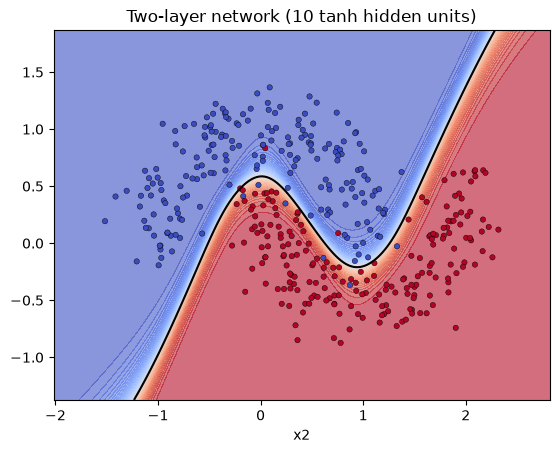

In [17]:
if __name__ == "__main__":
    H = 10
    grad_check(X, y, init_params(X.shape[1], H, np.random.default_rng(1)))
    params = train(X, y, n_hidden = H)
    plot_decision_boundary(lambda P: forward(P, params)[0], X, y, title = f"Two-layer network ({H} tanh hidden units)")

In [14]:
acc = np.mean((forward(X, params)[0]>0.5) == y)
Test_acc = np.mean((forward(X_test, params)[0]>0.5) == y_test)
print(f"Training accuracy is {acc:3f} and test accuracy is {Test_acc:3f}")

Training accuracy is 0.977500 and test accuracy is 0.970000
